In [1]:
import xarray as xr
import numpy as np

In [2]:
with open("LASE_V11", "r", encoding="utf-8") as f:
    lase = f.read()
lase

In [3]:
nlon = 36000
ntotal = len(lase)
nlat = int(ntotal / nlon)
nlon, nlat

(36000, 18000)

In [4]:
mask = np.frombuffer(lase.encode("ascii"), dtype=np.uint8) - ord("0")
mask = mask.reshape(nlat, nlon)
mask

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(18000, 36000), dtype=uint8)

In [5]:
latitudes = 90 - (np.arange(nlat) + 0.5) * (180 / nlat)
longitudes = -180 + (np.arange(nlon) + 0.5) * (360 / nlon)

In [9]:
ds_validat = xr.Dataset(
    data_vars = {
        "lsm": (
            ("latitude", "longitude"), 
            mask.astype(np.uint8),
            {
                "standard_name": "land_binary_mask",
                "long_name": "Land-sea mask",
                "flag_values": np.array([0, 1], dtype=np.uint8),
                "flag_meanings": "sea land",
            },
        )
    },
    coords = {
        "latitude": (
            "latitude", 
            latitudes,
            {
                "standard_name": "latitude",
                "long_name": "latitude",
                "units": "degrees_north",
                "axis": "Y",
            },
        ),
        "longitude": (
            "longitude", 
            longitudes,
            {
                "standard_name": "longitude",
                "long_name": "longitude",
                "units": "degrees_east",
                "axis": "X",
            },
        ),
    },
    attrs = {
        "Conventions": "CF-1.10",
        "title": "Land-sea mask",
        "insitution": "Deutscher Wetterdienst",
        "source": "ASCII validat land-sea mask LASE_V11",
    }
)
ds

<xarray.Dataset> Size: 648MB
Dimensions:    (latitude: 18000, longitude: 36000)
Coordinates:
  * latitude   (latitude) float64 144kB 90.0 89.98 89.97 ... -89.97 -89.99 -90.0
  * longitude  (longitude) float64 288kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    lsm        (latitude, longitude) uint8 648MB 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1
Attributes:
    Conventions:  CF-1.10
    title:        Land-sea mask
    insitution:   Deutscher Wetterdienst
    source:       ASCII validat land-sea mask LASE_V11

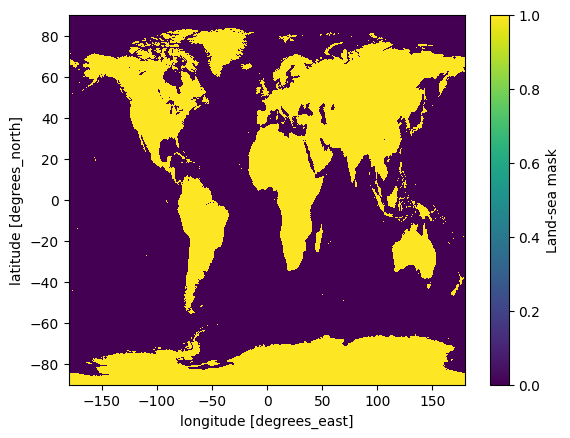

In [10]:
ds_validat.lsm.isel(
    latitude=slice(None, None, 10),
    longitude=slice(None, None, 10)
).plot()

In [12]:
ds_validat.to_netcdf("LASE_V11.nc", encoding={"lsm": {"zlib": True, "complevel": 4}})

In [13]:
ds_icoads = xr.open_dataset("LLN2F1.nc")
ds_icoads

C:\Users\llierham\mobaxterm\.venvs\mp_py\Lib\site-packages\xarray\coding\times.py:215: SerializationWarning: Ambiguous reference date string: 1-1-1 00:00:00. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0001-1-1 00:00:00). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)
C:\Users\llierham\mobaxterm\slash\tmp\ipykernel_6844\4032182772.py:1: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates prior reform date (1582-10-15). To silence this warning specify 'use_cftime=True'.
  ds_icoads = xr.open_dataset("LLN2F1.nc")


<xarray.Dataset> Size: 67kB
Dimensions:  (time: 1, lat: 90, lon: 180)
Coordinates:
  * time     (time) object 8B 0001-01-01 00:00:00
  * lat      (lat) float64 720B 89.0 87.0 85.0 83.0 ... -83.0 -85.0 -87.0 -89.0
  * lon      (lon) float64 1kB 1.0 3.0 5.0 7.0 9.0 ... 353.0 355.0 357.0 359.0
Data variables:
    land     (time, lat, lon) float32 65kB ...
Attributes:
    CDI:          Climate Data Interface version 2.5.2 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Tue Nov 03 12:28:49 2026: cdo -f nc import_binary LLN2F1.ct...
    CDO:          Climate Data Operators version 2.5.2 (https://mpimet.mpg.de...

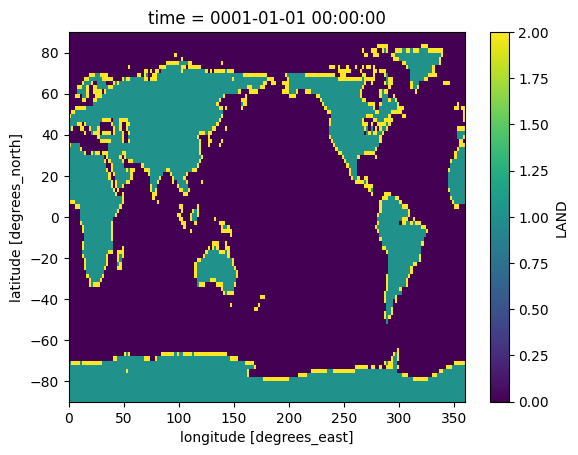

In [14]:
ds_icoads.land.plot()

In [16]:
ds_osm = xr.open_dataset("osm_land_mask.nc")
ds_osm

<xarray.Dataset> Size: 934MB
Dimensions:  (lat: 21600, lon: 43200)
Coordinates:
  * lat      (lat) float64 173kB -90.0 -89.99 -89.98 -89.97 ... 89.98 89.99 90.0
  * lon      (lon) float64 346kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
Data variables:
    land     (lat, lon) int8 933MB ...
Attributes:
    Conventions:  CF-1.8
    title:        Global 30 arc-second land mask, navigable inland water as sea
    source:       OpenStreetMap land polygons (land-polygons-split-4326) minu...
    license:      OpenStreetMap data (c) OpenStreetMap contributors, ODbL 1.0...
    history:      2026-11-03: built by gdacinter build_osm_landmask

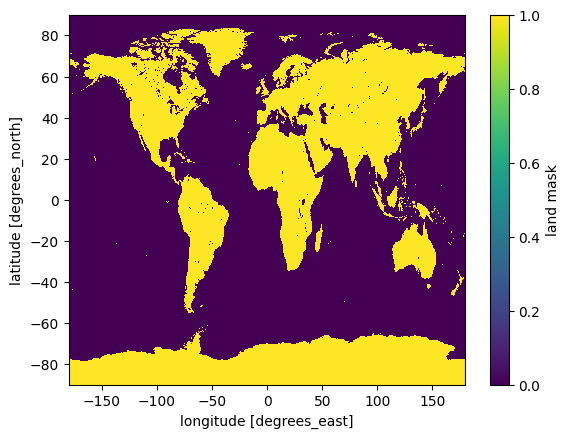

In [19]:
ds_osm.land.isel(
    lat=slice(None, None, 10),
    lon=slice(None, None, 10)
).plot()